# 05 · Người bán — Quyết định ④: mở rộng thu hút nhóm người bán nào?

Notebook giải trình cho trang Power BI **p6 "Người bán"**.

| # | Câu hỏi | Mục |
|---|---|---|
| 1 | Người bán đang ở quy mô nào; cung có tăng nhanh hơn cầu? | §1 |
| 2 | Người bán phân tầng thế nào? Nhóm nào nuôi sàn? | §2 |
| 3 | Doanh thu đến từ người bán lâu năm hay người bán mới? Người bán có ở lại không? | §3 |
| 4 | Ngành nào phụ thuộc vào vài người bán? Bán nhiều ngành có đi kèm doanh thu cao hơn? | §4 |
| 5 | Bao nhiêu doanh thu đang nằm trong tay người bán phục vụ kém? | §5 |
| 6 | Phân tầng chất lượng người bán: ai là "vùng đỏ", ai là "ngôi sao"? Ai gây ra phần lớn đơn không hài lòng? | §6 |
| 7 | **Vùng nào, ngành nào đang thiếu người bán tại chỗ?** | §7 |
| 8 | Người bán bàn giao hàng mất bao lâu? Người bán nhiều đơn có bị quá tải không? | §8 |

§9 đối chiếu với Gold, §10 chỉ rõ biểu đồ nào đứng sau visual nào trên trang p6.

### Quy ước
- **Tập đơn:** mọi biểu đồ tính trên **dòng sản phẩm thuộc đơn hợp lệ** (đơn có sản phẩm, trạng thái khác `canceled` / `unavailable`), trừ khi tiêu đề ghi khác.
  Riêng §5: điểm review tính trên đơn có review, % giao trễ tính trên đơn đã giao.
- **Doanh thu (GMV)** = `price + freight_value` (BRL).
- **Người bán** = `seller_key`. **Sản phẩm (SKU)** = `product_id`. **Số sản phẩm đã bán** = số dòng trong `fact_order_items` (1 dòng = 1 sản phẩm; khác với số SKU).
- **Ngành hàng** = tên tiếng Anh, thiếu thì tên gốc, thiếu cả hai thì `unknown` (`CATEGORY_SQL`, giống Gold).
- **Kỳ** (cùng quy tắc với Gold / Power BI, in ở §0): kỳ này = 01 → tháng báo cáo suy từ dữ liệu, so với cùng kỳ năm trước (YoY) và quý trước (QoQ);
  ghi đè bằng `REPORT_START` / `REPORT_END`. Biểu đồ theo tháng dùng cửa sổ xu hướng 01/năm trước → tháng báo cáo.
- Tầng người bán, mức điểm review, cửa sổ "còn bán" lấy từ Gold (`GOLD.SELLER_TIERS`, `GOLD.SELLER_REVIEW_BANDS`…). Ngưỡng **chỉ có ở EDA** (rủi ro review, tập trung top 3, vùng đỏ / ngôi sao ở §6) khai báo một lần ở cell cấu hình bên dưới và **không có trên Power BI**.
- Kết nối, kỳ phân tích, bảng màu, hàm trục, KPI, bảng `order_base` / `item_ps` và ngưỡng `MIN_SELLER_ORDERS` lấy từ package `common`.

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from common import *   # kết nối, kỳ phân tích, bảng màu, hàm trục, KPI, item_ps

con, P = connect(["sellers", "products", "categories"])
apply_theme()

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | quý 07–08/2018 vs 04–05/2018 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
# ---------- Ngưỡng phân tích (khai báo một lần, dùng cho mọi phần) ----------
SELLER_TIER_EDGES = band_edges(GOLD.SELLER_TIERS)                # GMV toàn kỳ của người bán (BRL)
SELLER_TIER_NAMES = ["Siêu nhỏ", "Nhỏ", "Vừa", "Lớn", "Chiến lược"]
TOP_TIERS = ["Lớn", "Chiến lược"]
CATEGORY_COUNT_EDGES = band_edges(GOLD.CATEGORY_COUNT_BANDS)     # số ngành người bán bán (khoảng đóng bên phải)
CATEGORY_COUNT_LABELS = band_order(GOLD.CATEGORY_COUNT_BANDS)
ACTIVE_FROM_MONTH, ACTIVE_TO_MONTH = GOLD.ACTIVE_FROM_MONTH, GOLD.ACTIVE_TO_MONTH   # "còn bán" = có đơn ở tháng thứ 6–8 sau tháng đầu
REVIEW_EDGES = band_edges(GOLD.SELLER_REVIEW_BANDS)
RISK_REVIEW = 3.8                                                # điểm review dưới mức này = doanh thu rủi ro
GOOD_REVIEW = 4.0                                                # từ mức này trở lên = phục vụ tốt
assert RISK_REVIEW in REVIEW_EDGES and GOOD_REVIEW in REVIEW_EDGES
TOP3_HIGH, TOP3_MEDIUM = 0.40, 0.25                              # tỷ trọng top 3 người bán trong ngành: cao / trung bình

SELLER_TIER_LABELS = [f"{n} ({r})" for n, r in zip(SELLER_TIER_NAMES, band_labels(SELLER_TIER_EDGES, lambda v: f"{v/1e3:g}K"))]
TOP_TIER_LABELS = [l for n, l in zip(SELLER_TIER_NAMES, SELLER_TIER_LABELS) if n in TOP_TIERS]
REVIEW_LABELS = band_labels(REVIEW_EDGES, lambda v: f"{v:.1f}")

# ---------- Ngưỡng chỉ có ở EDA (§6), áp cho người bán có ≥ MIN_SELLER_ORDERS đơn hợp lệ trong kỳ này ----------
RED_LATE, RED_REVIEW = 0.20, 3.5      # "vùng đỏ": % đơn giao trễ > 20% HOẶC điểm review < 3,5
STAR_LATE, STAR_REVIEW = 0.08, 4.2    # "ngôi sao": % đơn giao trễ ≤ 8% VÀ điểm review ≥ 4,2
PBI_MIN_SELLER_ORDERS = 10            # scatter p6 chỉ vẽ người bán ≥ 10 đơn trong kỳ (measure 'Seller Quality …')
CX_METRICS = "count(*) AS orders, avg(review_score) AS avg_score, avg(is_negative) AS negative_rate"

### Tạo bảng phân tích
- `item_ps`: **1 dòng / đơn vị sản phẩm trong đơn hợp lệ**: thời gian mua, ngành, SKU, người bán (bang/vùng), khách (bang), giá, phí ship, GMV.
  Tạo bằng `create_item_ps()` của `common/tables.py`, dùng chung với notebook `03_product` nên hai notebook ra cùng con số.
- `order_q`: chỉ số chất lượng **theo đơn hợp lệ** (điểm review TB, cờ không hài lòng, cờ giao trễ), lấy từ `order_base`.
- `seller_ps` → DataFrame `sellers`: **1 dòng / người bán**, gom mọi thuộc tính dùng ở §2–§5 (quy mô, độ rộng danh mục, cohort, cờ còn bán, chất lượng, hạng GMV)
  để các phần sau chỉ đọc, không thêm cột. Cohort trước cửa sổ xu hướng được gộp theo năm, từ đó trở đi theo quý.

In [3]:
create_item_ps()
con.execute("CREATE OR REPLACE TABLE order_q AS SELECT order_id, review_score, is_negative, is_late FROM order_base WHERE is_valid = 1")
con.execute(f"""
CREATE OR REPLACE TABLE seller_ps AS
WITH base AS (
    SELECT seller_id, arbitrary(seller_state) AS seller_state,
           arbitrary(seller_region) AS seller_region, sum(gmv) AS gmv, count(*) AS units,
           count(DISTINCT order_id) AS orders, count(DISTINCT product_id) AS skus, count(DISTINCT category) AS n_categories,
           count(DISTINCT customer_state) AS n_customer_states, avg(price) AS avg_price, min(purchase_month) AS first_month
    FROM item_ps GROUP BY 1),
quality AS (   -- điểm review / không hài lòng: đơn có review; giao trễ: đơn đã giao
    SELECT so.seller_id, avg(oq.review_score) AS avg_review, avg(oq.is_negative) AS negative_rate, avg(oq.is_late) AS late_rate
    FROM (SELECT DISTINCT seller_id, order_id FROM item_ps) so JOIN order_q oq USING (order_id) GROUP BY 1),
activity AS (  -- có bán trong tháng thứ {ACTIVE_FROM_MONTH}–{ACTIVE_TO_MONTH} sau tháng đầu tiên?
    SELECT b.seller_id,
           max(CAST(m.purchase_month BETWEEN b.first_month + INTERVAL '{ACTIVE_FROM_MONTH}' MONTH
                                         AND b.first_month + INTERVAL '{ACTIVE_TO_MONTH}' MONTH AS INTEGER)) AS active_later
    FROM base b JOIN (SELECT DISTINCT seller_id, purchase_month FROM item_ps) m ON m.seller_id = b.seller_id GROUP BY 1)
SELECT b.*,
       CASE WHEN b.first_month < DATE '{P.m_start}' THEN CAST(year(b.first_month) AS VARCHAR)
            ELSE CAST(year(b.first_month) AS VARCHAR) || '-Q' || CAST(quarter(b.first_month) AS VARCHAR) END AS cohort,
       -- chỉ cohort đã có đủ {ACTIVE_TO_MONTH} tháng quan sát mới được tính tỷ lệ còn bán (tránh lệch do dữ liệu bị cắt ở tháng báo cáo)
       b.first_month + INTERVAL '{ACTIVE_TO_MONTH}' MONTH <= DATE '{P.m_end}' AS retention_observable,
       a.active_later, qa.avg_review, qa.negative_rate, qa.late_rate,
       rank() OVER (ORDER BY b.gmv DESC) AS gmv_rank
FROM base b LEFT JOIN quality qa ON qa.seller_id = b.seller_id LEFT JOIN activity a ON a.seller_id = b.seller_id
""")

sellers = q("SELECT * FROM seller_ps")
sellers["tier"] = pd.cut(sellers.gmv, SELLER_TIER_EDGES, labels=SELLER_TIER_LABELS, right=False)
sellers["category_count_band"] = pd.cut(sellers.n_categories, CATEGORY_COUNT_EDGES, labels=CATEGORY_COUNT_LABELS)
sellers["review_band"] = pd.cut(sellers.avg_review.where(sellers.orders >= MIN_SELLER_ORDERS), REVIEW_EDGES,
                                labels=REVIEW_LABELS, right=False)
TOTAL_GMV = sellers.gmv.sum()

print(q("""SELECT count(*) AS valid_items, count(DISTINCT order_id) AS valid_orders, count(DISTINCT product_id) AS skus,
                  count(DISTINCT seller_id) AS sellers, count(DISTINCT category) AS categories,
                  round(sum(gmv) / 1e6, 2) AS gmv_mil
           FROM item_ps""").to_string(index=False))

# Bảng trải nghiệm cho §6 (mọi đơn, giống customer_experience cũ): order_cx = order_base; delivered = đơn đã giao đủ ngày
con.execute("CREATE OR REPLACE TABLE order_cx AS SELECT * FROM order_base")
_ = con.execute("CREATE OR REPLACE TABLE delivered AS SELECT * FROM order_cx WHERE is_late IS NOT NULL AND delivery_days IS NOT NULL")

 valid_items  valid_orders  skus  sellers  categories  gmv_mil
      110500         96817 32399     3042          74    15.53


## 1. KPI & năng suất người bán theo tháng
*Câu hỏi: "Sàn có bao nhiêu người bán hoạt động, mỗi người bán tạo bao nhiêu doanh thu? Nguồn cung có đang tăng nhanh hơn nhu cầu không?"*

Bảng đầu: chỉ số người bán (so sánh bằng `COMPARE` trong `common/period.py`). Bảng thứ hai: **các thẻ KPI của trang p6** (kỳ này).
GMV toàn sàn không lặp lại ở đây (xem `01_executive_overview` §1).
- **Người bán hoạt động** trong tháng = người bán có ít nhất 1 sản phẩm trong đơn hợp lệ của tháng đó. **Người bán mới** = người bán có tháng bán đầu tiên là tháng đó.

In [4]:
def seller_kpis(where: str) -> dict:
    k = q(f"""SELECT sum(gmv) AS gmv, count(*) AS units, count(DISTINCT product_id) AS skus,
                     count(DISTINCT seller_id) AS sellers
              FROM item_ps WHERE {where}""").iloc[0].to_dict()
    k["gmv_per_seller"] = k["gmv"] / k["sellers"]
    k["units_per_seller"] = k["units"] / k["sellers"]
    k["skus_per_seller"] = k["skus"] / k["sellers"]
    return k

KPIS = [
    Kpi("gmv", "Doanh thu GMV (BRL)", "{:,.0f}", "pct"),
    Kpi("sellers", "Người bán hoạt động", "{:,.0f}", "pct"),
    Kpi("gmv_per_seller", "GMV / người bán (BRL)", "{:,.0f}", "pct"),
    Kpi("units_per_seller", "Số sản phẩm đã bán / người bán", "{:,.1f}", "pct"),
    Kpi("skus_per_seller", "SKU / người bán", "{:,.1f}", "pct"),
]
print(kpi_table(KPIS, seller_kpis, P).to_string())

                               01–08/2017 01–08/2018 Thay đổi YoY Quý trước (04–05/2018) Quý này (07–08/2018) Thay đổi QoQ
Chỉ số                                                                                                                    
Doanh thu GMV (BRL)             3,564,588  8,398,428      +135.6%              2,228,699            1,939,839       -13.0%
Người bán hoạt động                 1,208      2,344       +94.0%                  1,395                1,590       +14.0%
GMV / người bán (BRL)               2,951      3,583       +21.4%                  1,598                1,220       -23.6%
Số sản phẩm đã bán / người bán       21.1       25.5       +20.8%                   11.0                  8.5       -22.6%
SKU / người bán                       8.1        8.5        +5.8%                    5.0                  4.5       -10.0%


In [5]:
# Thẻ KPI trang p6 (toàn quốc, kỳ này)
def p6_cards(where: str) -> dict:
    inter = scalar(f"SELECT avg(CAST(seller_region <> customer_region AS DOUBLE)) FROM item_ps WHERE {where} AND seller_region IS NOT NULL")
    # SLA theo NGÀY LỊCH (date_diff trên ngày, giống Gold / thẻ Power BI); delivery_days của Silver là hiệu timestamp / 86400
    sla = q(f"""SELECT avg(date_diff('day', CAST(f.order_purchase_timestamp AS DATE), CAST(f.order_delivered_customer_date AS DATE))) AS actual,
                        avg(date_diff('day', CAST(f.order_purchase_timestamp AS DATE), CAST(f.order_estimated_delivery_date AS DATE))) AS promised
                 FROM order_base b JOIN orders f ON f.order_id = b.order_id
                 WHERE b.is_valid = 1 AND b.is_late IS NOT NULL AND {where.replace('purchase_month', 'b.purchase_month')}""").iloc[0]
    dens = q(f"""SELECT count(DISTINCT seller_id) AS sellers, count(DISTINCT customer_unique_id) AS customers
                  FROM item_ps WHERE {where}""").iloc[0]
    return {"inter_region": inter, "sla_actual": sla.actual, "sla_promised": sla.promised,
            "density": dens.sellers / dens.customers * 1000}

cards = {P.label_prev: p6_cards(P.prev), P.label_cur: p6_cards(P.cur)}
print(pd.DataFrame(cards).rename(index={"inter_region": "Tỷ lệ giao liên vùng", "sla_actual": "Giao thực tế TB (ngày)",
                                        "sla_promised": "Cam kết TB (ngày)", "density": "Mật độ người bán (người / 1.000 KH)"})
      .round(3).to_string())

                                     01–08/2017  01–08/2018
Tỷ lệ giao liên vùng                      0.393       0.367
Giao thực tế TB (ngày)                   12.198      12.163
Cam kết TB (ngày)                        26.026      23.438
Mật độ người bán (người / 1.000 KH)      55.266      45.873


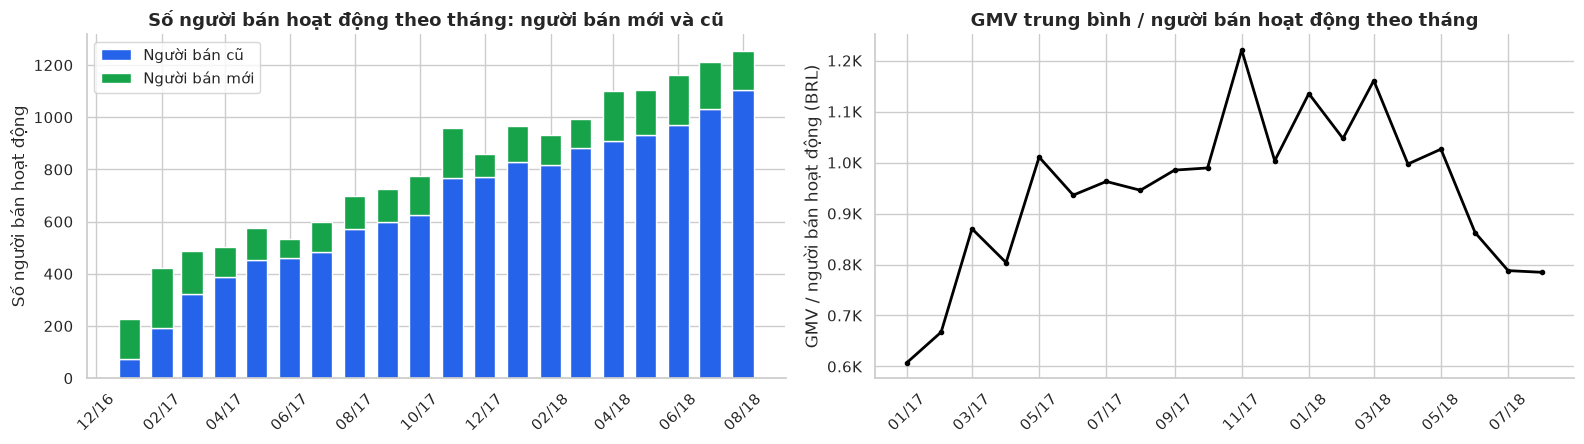

01–08/2017: người bán HĐ TB/tháng 506 | người bán mới TB/tháng 138 | GMV/người bán 851
01–08/2018: người bán HĐ TB/tháng 1,091 | người bán mới TB/tháng 157 | GMV/người bán 975
GMV/người bán: đỉnh 03/2018 1,161 → 08/2018 785 (-32%)
01/2018 → 08/2018: người bán HĐ 968 → 1,255 (+30%) | số đơn 7,162 → 6,335 (-12%)


In [6]:
# Người bán hoạt động (mới / cũ) và GMV trên mỗi người bán hoạt động, theo tháng
monthly_supply = q(f"""WITH seller_first AS (SELECT seller_id, min(purchase_month) AS first_month FROM item_ps GROUP BY 1)
                       SELECT i.purchase_month AS month, count(DISTINCT i.seller_id) AS active_sellers,
                              count(DISTINCT i.seller_id) FILTER (WHERE f.first_month = i.purchase_month) AS new_sellers,
                              count(DISTINCT i.order_id) AS orders, sum(i.gmv) AS gmv
                       FROM item_ps i JOIN seller_first f ON f.seller_id = i.seller_id
                       WHERE {P.in_period} GROUP BY 1 ORDER BY 1""")
monthly_supply["month"] = pd.to_datetime(monthly_supply.month)
monthly_supply["gmv_per_seller"] = monthly_supply.gmv / monthly_supply.active_sellers

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.6))
ax1.bar(monthly_supply.month, monthly_supply.active_sellers - monthly_supply.new_sellers, width=20, color=C_MAIN, label="Người bán cũ")
ax1.bar(monthly_supply.month, monthly_supply.new_sellers, width=20, bottom=monthly_supply.active_sellers - monthly_supply.new_sellers,
        color=C_GOOD, label="Người bán mới")
ax1.set_ylabel("Số người bán hoạt động"); month_axis(ax1); ax1.legend(loc="upper left")
ax1.set_title("Số người bán hoạt động theo tháng: người bán mới và cũ")
ax2.plot(monthly_supply.month, monthly_supply.gmv_per_seller, color="black", marker="o", ms=3, lw=2)
brl_axis(ax2, unit="K"); ax2.set_ylabel("GMV / người bán hoạt động (BRL)"); month_axis(ax2)
ax2.set_title("GMV trung bình / người bán hoạt động theo tháng")
plt.tight_layout(); plt.show()

supply_by_month = monthly_supply.set_index("month")
def months_of(year):   # các tháng 01 → tháng báo cáo của một năm
    idx = supply_by_month.index
    return supply_by_month[(idx.year == year) & (idx.month <= P.last_mon)]
supply_prev, supply_cur = months_of(P.year_prev), months_of(P.year_cur)
for year, period in [(P.year_prev, supply_prev), (P.year_cur, supply_cur)]:
    print(f"{P.label(year)}: người bán HĐ TB/tháng {period.active_sellers.mean():,.0f} | người bán mới TB/tháng {period.new_sellers.mean():,.0f} | "
          f"GMV/người bán {period.gmv_per_seller.mean():,.0f}")
peak_month = supply_cur.gmv_per_seller.idxmax()
first, last = supply_cur.iloc[0], supply_cur.iloc[-1]
print(f"GMV/người bán: đỉnh {peak_month:%m/%Y} {supply_cur.gmv_per_seller[peak_month]:,.0f} → {last.name:%m/%Y} {last.gmv_per_seller:,.0f} "
      f"({last.gmv_per_seller / supply_cur.gmv_per_seller[peak_month] - 1:+.0%})")
print(f"{first.name:%m/%Y} → {last.name:%m/%Y}: người bán HĐ {first.active_sellers:,.0f} → {last.active_sellers:,.0f} ({last.active_sellers / first.active_sellers - 1:+.0%}) | "
      f"số đơn {first.orders:,.0f} → {last.orders:,.0f} ({last.orders / first.orders - 1:+.0%})")

> **🔎 Kết quả chính**
> - So 2 kỳ 8 tháng: người bán hoạt động **+94%**, chậm hơn GMV (+135,6%), nên **GMV / người bán +21,4%** (2.951 → 3.583 BRL).
> - Nhưng **cung đang vượt cầu trong 2018**: 01 → 08/2018 người bán hoạt động **+30%** (968 → 1.255) trong khi số đơn **−12%** (7.162 → 6.335); GMV / người bán hoạt động giảm từ đỉnh 1.161 BRL (03/2018) xuống 785 BRL (08/2018, **−32%**). QoQ cũng vậy: người bán +14,0%, GMV −13,0%, GMV / người bán −23,6%. Mỗi tháng vẫn có thêm ~157 người bán mới.
> - Thẻ p6 (kỳ này so với cùng kỳ): tỷ lệ giao liên vùng 39,3% → 36,7%; giao thực tế / cam kết **12,2 / 23,4 ngày** (cùng kỳ 12,2 / 26,0 — giao không nhanh hơn, chỉ hứa sớm hơn); mật độ người bán 55,3 → 45,9 người / 1.000 khách.
> - *Lưu ý*: thẻ SLA tính theo **ngày lịch** như Gold / Power BI, nên cao hơn ~0,4 ngày so với `delivery_days` của Silver dùng ở các notebook khác.
> - → Nếu doanh số mỗi người bán tiếp tục giảm, sàn có nguy cơ **mất người bán**: quyết định ④ nên là tuyển **có chọn lọc** (đúng vùng, đúng ngành — §7), không tuyển đại trà.

## 2. Phân tầng người bán theo doanh thu
*Câu hỏi: "Người bán phân hóa thế nào? Nhóm nào thực sự nuôi sàn?"*

Chia người bán thành **5 tầng theo tổng GMV toàn kỳ**
và so sánh quy mô, độ rộng danh mục, phạm vi thị trường của từng tầng.
Tầng người bán theo `GOLD.SELLER_TIERS` (giống `dim_seller.seller_tier` và visual *Tỷ trọng người bán và GMV theo tầng người bán* trên p6).

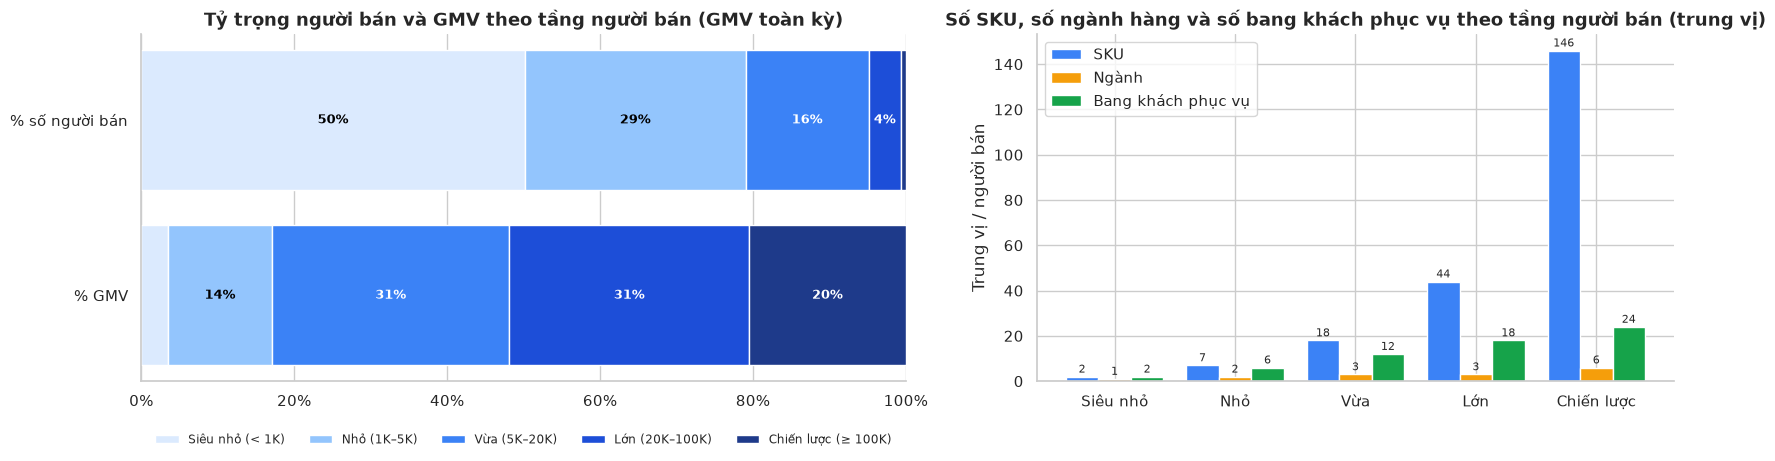

                     sellers         gmv  median_gmv  median_skus  median_categories  median_states  median_price  seller_share  gmv_share
tier                                                                                                                                      
Siêu nhỏ (< 1K)         1527   545212.66     274.860          2.0                1.0            2.0        69.000         0.502      0.035
Nhỏ (1K–5K)              878  2112297.40    2085.930          7.0                2.0            6.0       123.816         0.289      0.136
Vừa (5K–20K)             490  4821359.06    8743.295         18.0                3.0           12.0       130.189         0.161      0.311
Lớn (20K–100K)           128  4868028.65   34325.440         44.0                3.0           18.0       147.916         0.042      0.314
Chiến lược (≥ 100K)       19  3179108.64  156616.490        146.0                6.0           24.0       132.478         0.006      0.205

556 người bán (18.3%) tạo 

In [7]:
tiers = sellers.groupby("tier", observed=False).agg(sellers=("seller_id", "size"), gmv=("gmv", "sum"), median_gmv=("gmv", "median"),
                                                    median_skus=("skus", "median"), median_categories=("n_categories", "median"),
                                                    median_states=("n_customer_states", "median"), median_price=("avg_price", "median"))
tiers["seller_share"] = tiers.sellers / tiers.sellers.sum(); tiers["gmv_share"] = tiers.gmv / tiers.gmv.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.2, 1]})
for row, column in enumerate(["seller_share", "gmv_share"]):
    left = 0
    for tier_label, color in zip(SELLER_TIER_LABELS, SEQ_BLUES):
        value = tiers.loc[tier_label, column]
        ax1.barh(row, value, left=left, color=color, edgecolor="white", label=tier_label if row == 0 else None)
        if value > 0.04:
            ax1.text(left + value / 2, row, f"{value:.0%}", ha="center", va="center", fontsize=9.5,
                     color="white" if SELLER_TIER_LABELS.index(tier_label) >= 2 else "black", fontweight="bold")
        left += value
ax1.set_yticks([0, 1], ["% số người bán", "% GMV"]); pct_axis(ax1, "x"); ax1.set_xlim(0, 1); ax1.invert_yaxis()
ax1.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=8.5, frameon=False)
ax1.set_title("Tỷ trọng người bán và GMV theo tầng người bán (GMV toàn kỳ)")

profile = tiers[["median_skus", "median_categories", "median_states"]]
x = np.arange(len(profile)); width = 0.27
for j, (column, label, color) in enumerate([("median_skus", "SKU", SEQ_BLUES[2]), ("median_categories", "Ngành", C_ACCENT),
                                            ("median_states", "Bang khách phục vụ", C_GOOD)]):
    profile_bars = ax2.bar(x + (j - 1) * width, profile[column], width, color=color, label=label)
    ax2.bar_label(profile_bars, labels=[f"{v:.0f}" for v in profile[column]], fontsize=8, padding=1)
ax2.set_xticks(x, SELLER_TIER_NAMES); ax2.legend(); ax2.set_ylabel("Trung vị / người bán")
ax2.set_title("Số SKU, số ngành hàng và số bang khách phục vụ theo tầng người bán (trung vị)")
plt.tight_layout(); plt.show()
print(tiers.round(3).to_string())
top_tier_mask = sellers.tier.isin(TOP_TIER_LABELS)
pareto = sellers.gmv.sort_values(ascending=False).cumsum() / TOTAL_GMV
n80 = int((pareto < 0.8).sum() + 1)
print(f"\n{n80:,} người bán ({n80 / len(sellers):.1%}) tạo 80% GMV; top 1% người bán tạo {pareto.iloc[int(len(sellers) * 0.01) - 1]:.1%} GMV; "
      f"người bán lớn nhất chiếm {sellers.gmv.max() / TOTAL_GMV:.2%}")
print(f"Tầng {' + '.join(TOP_TIERS)}: {top_tier_mask.sum()} người bán ({top_tier_mask.mean():.1%}) = {sellers.gmv[top_tier_mask].sum() / TOTAL_GMV:.1%} GMV")

> **🔎 Kết quả chính**
> - **Một nửa số người bán (1.527) là "siêu nhỏ"** (< 1.000 BRL cả kỳ, trung vị 275 BRL), chỉ tạo **3,5% GMV**.
> - Pareto rõ: **556 người bán (18,3%) tạo 80% GMV**, top 1% tạo 25,4%; người bán lớn nhất chỉ chiếm 1,6% → sàn không phụ thuộc vào một cá nhân.
> - **147 người bán tầng Lớn + Chiến lược (4,8%) tạo 51,8% GMV**, riêng **19 người bán chiến lược (≥ 100K BRL) tạo 20,5%**. Ba tầng trên cùng (21% người bán) gánh **83% doanh thu**.
> - Người bán lớn khác biệt chủ yếu ở **độ rộng**: trung vị 146 SKU, 6 ngành, 24 bang (chiến lược) so với 2 SKU, 1 ngành, 2 bang (siêu nhỏ); giá TB / đơn vị chênh ít hơn.

## 3. Vòng đời người bán: doanh thu đến từ người bán cũ hay mới?
*Câu hỏi: "Doanh thu mỗi tháng do người bán gia nhập từ lúc nào tạo ra? Người bán có tiếp tục bán không?"*

- **Cohort người bán** = quý có đơn hợp lệ đầu tiên của người bán *trong dữ liệu* (trước cửa sổ xu hướng thì gộp theo năm). Dữ liệu 2016 rất mỏng, nên cohort *2016* và *2017-Q1*
  gồm cả người bán **đã có từ trước** khi dữ liệu bắt đầu (bị cắt trái), không thuần là người bán mới.
- **Biểu đồ "bánh nhiều lớp"** (layer cake): GMV mỗi tháng xếp chồng theo cohort.
- **Tỷ lệ còn bán** = % người bán có đơn trong **tháng thứ 6–8 sau tháng đầu tiên**. Mọi cohort được đo **cùng một độ tuổi**,
  và chỉ tính người bán có tháng đầu ≤ 12/2017 (đủ 8 tháng quan sát trước 08/2018), để cohort mới không được lợi do bị cắt phải.

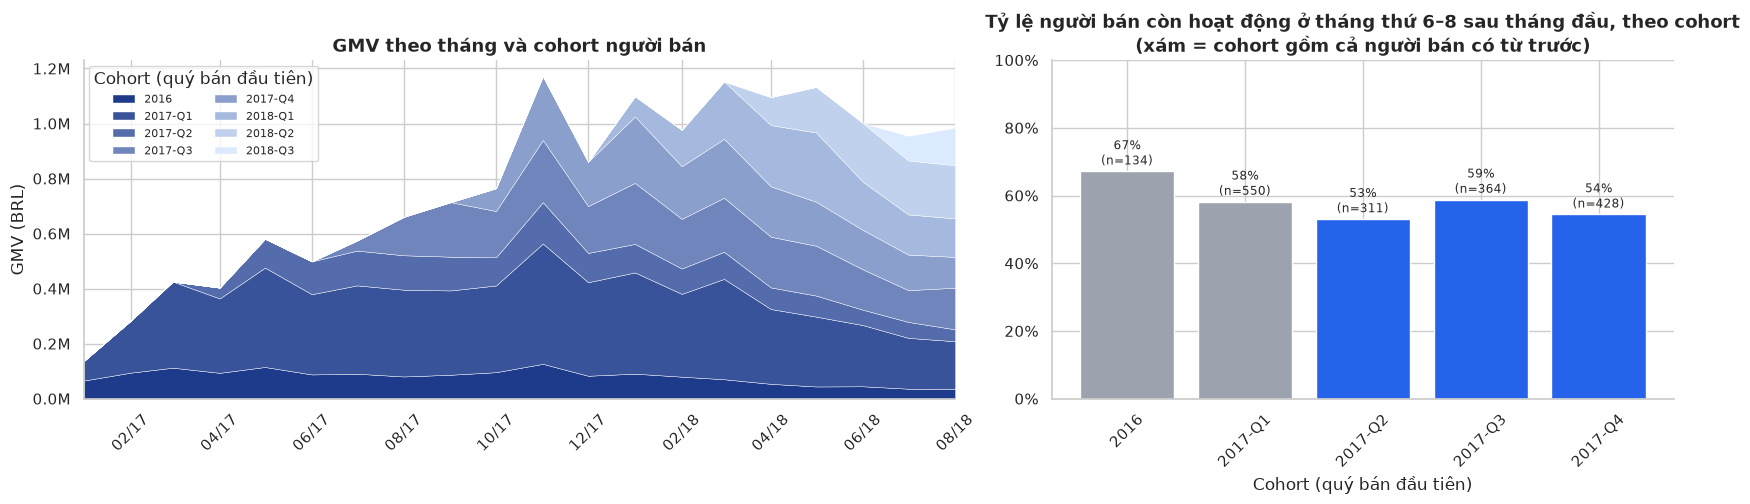

GMV 08/2018 từ người bán có đơn đầu tiên trong 2018: 47.7%; từ người bán có trước 2018: 52.3%
Tỷ trọng GMV 01–08/2018 theo cohort:
cohort
2016       0.054
2017-Q1    0.255
2017-Q2    0.072
2017-Q3    0.164
2017-Q4    0.164
2018-Q1    0.161
2018-Q2    0.104
2018-Q3    0.027
         sellers  active_later  median_gmv
cohort                                    
2016         134         0.672    4726.165
2017-Q1      550         0.582    2490.785
2017-Q2      311         0.531    1292.860
2017-Q3      364         0.588    1728.840
2017-Q4      428         0.544    1472.940


In [8]:
cohort_gmv = q(f"""SELECT i.purchase_month AS month, s.cohort, sum(i.gmv) AS gmv
                   FROM item_ps i JOIN seller_ps s ON s.seller_id = i.seller_id
                   WHERE {P.in_period} GROUP BY 1, 2""")
cohort_gmv["month"] = pd.to_datetime(cohort_gmv.month)
cohort_layers = cohort_gmv.pivot_table(index="month", columns="cohort", values="gmv", aggfunc="sum").fillna(0)
cohort_layers = cohort_layers[sorted(cohort_layers.columns)]
cohort_colors = sns.blend_palette([SEQ_BLUES[-1], SEQ_BLUES[0]], len(cohort_layers.columns))
# Cohort trước quý 2 của cửa sổ xu hướng gồm cả người bán đã có từ trước khi dữ liệu bắt đầu (bị cắt trái) → tô xám
LEFT_CENSORED_BEFORE = f"{P.year_prev}-Q2"

retention = (sellers[sellers.retention_observable].groupby("cohort")
             .agg(sellers=("seller_id", "size"), active_later=("active_later", "mean"), median_gmv=("gmv", "median")))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.2), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.stackplot(cohort_layers.index, cohort_layers.T.values, labels=cohort_layers.columns, colors=cohort_colors, edgecolor="white", lw=0.3)
brl_axis(ax1); month_axis(ax1); ax1.set_xlim(cohort_layers.index[0], cohort_layers.index[-1])
ax1.legend(title="Cohort (quý bán đầu tiên)", loc="upper left", fontsize=8, ncol=2)
ax1.set_title("GMV theo tháng và cohort người bán"); ax1.set_ylabel("GMV (BRL)")

retention_bars = ax2.bar(retention.index, retention.active_later,
                         color=[C_GREY if c < LEFT_CENSORED_BEFORE else C_MAIN for c in retention.index])
ax2.bar_label(retention_bars, labels=[f"{v:.0%}\n(n={n})" for v, n in zip(retention.active_later, retention.sellers)], fontsize=8.5, padding=2)
pct_axis(ax2); ax2.set_ylim(0, 1); ax2.tick_params(axis="x", rotation=45)
ax2.set_title(f"Tỷ lệ người bán còn hoạt động ở tháng thứ {ACTIVE_FROM_MONTH}–{ACTIVE_TO_MONTH} sau tháng đầu, theo cohort\n(xám = cohort gồm cả người bán có từ trước)")
ax2.set_xlabel("Cohort (quý bán đầu tiên)")
plt.tight_layout(); plt.show()

last_month = cohort_layers.loc[P.m_end]
from_cur_year = last_month[last_month.index >= str(P.year_cur)].sum() / last_month.sum()
print(f"GMV {pd.Timestamp(P.m_end):%m/%Y} từ người bán có đơn đầu tiên trong {P.year_cur}: {from_cur_year:.1%}; "
      f"từ người bán có trước {P.year_cur}: {1 - from_cur_year:.1%}")
gmv_cur = cohort_layers.loc[P.cur_start:P.m_end]
print(f"Tỷ trọng GMV {P.label_cur} theo cohort:"); print((gmv_cur.sum() / gmv_cur.sum().sum()).round(3).to_string())
print(retention.round(3).to_string())

> **🔎 Kết quả chính**
> - Người bán mới đóng góp lớn: ở 08/2018, **47,7% GMV** đến từ người bán có đơn đầu tiên trong 2018 → kênh tuyển người bán đang hiệu quả về doanh thu.
> - Cohort **2017-Q1** là lớp lớn nhất (25,5% GMV 01–08/2018) và co lại dần từ 03/2018.
> - **Tỷ lệ còn bán ổn định giữa các cohort**: ở tháng thứ 6–8, **53–59%** người bán gia nhập trong 2017 vẫn còn bán, tức **~4/10 người bán không còn đơn sau nửa năm**; không có dấu hiệu xấu đi theo thời gian.

## 4. Người bán × ngành hàng
*Câu hỏi: "Ngành nào phụ thuộc vào vài người bán? Người bán bán nhiều ngành có doanh thu cao hơn không?"*

- **Tỷ trọng top 3 người bán trong ngành** = GMV của 3 người bán lớn nhất ngành / GMV ngành. Cao → mất 1 người bán là ngành sụt mạnh.
- Xét 20 ngành lớn nhất theo GMV.

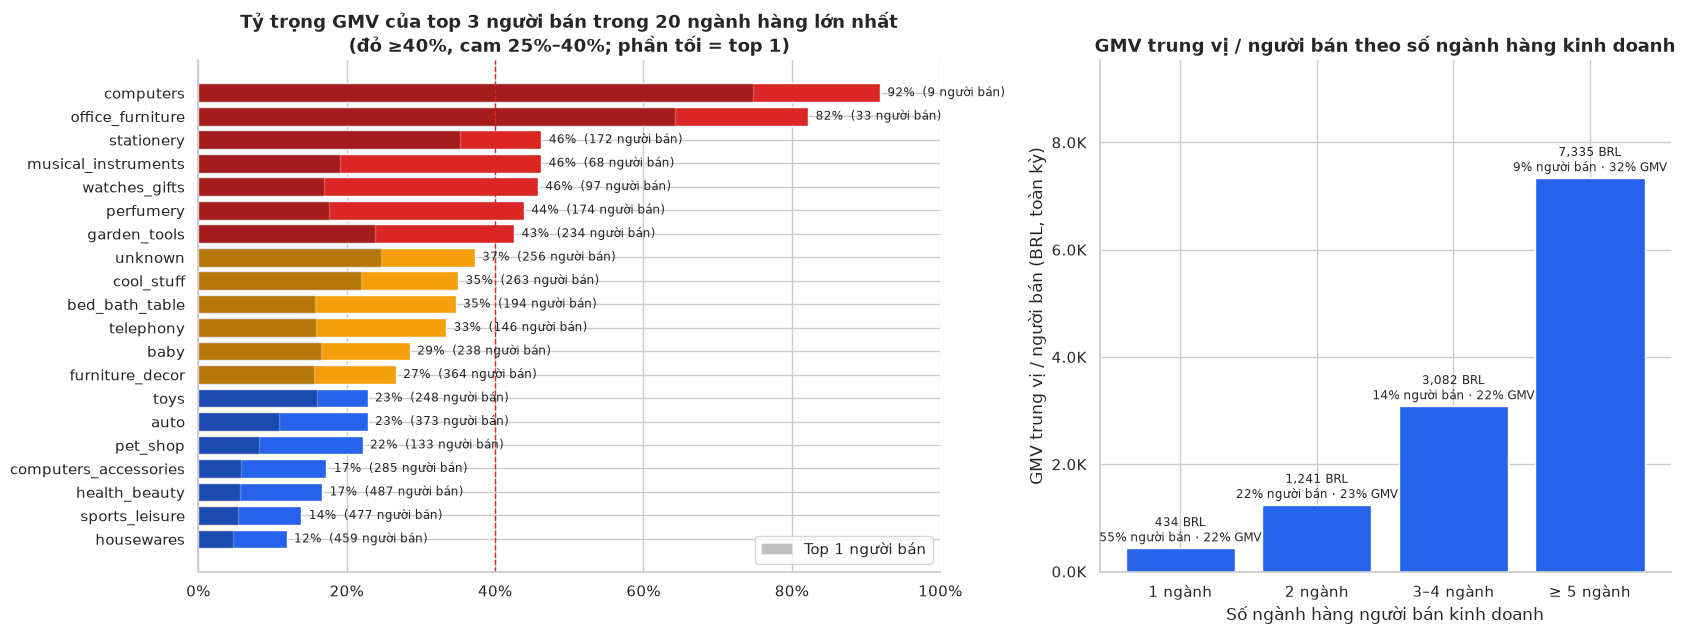

                              gmv  sellers   top1   top3
category                                                
computers               232799.43        9  0.747  0.919
office_furniture        341109.66       33  0.643  0.822
stationery              272932.37      172  0.353  0.463
musical_instruments     202270.27       68  0.191  0.462
watches_gifts          1281065.09       97  0.169  0.458
perfumery               444129.36      174  0.176  0.439
garden_tools            572816.06      234  0.238  0.426
unknown                 204630.42      256  0.247  0.373
cool_stuff              698670.41      263  0.219  0.350
bed_bath_table         1221656.20      194  0.157  0.347
telephony               389395.51      146  0.159  0.334
baby                    471517.03      238  0.166  0.285
furniture_decor         889048.73      364  0.156  0.266
toys                    549325.82      248  0.160  0.228
auto                    671731.82      373  0.110  0.228
pet_shop                248488.

In [9]:
category_seller = q("SELECT category, seller_id, sum(gmv) AS gmv FROM item_ps GROUP BY 1, 2")
category_seller["rank"] = category_seller.groupby("category").gmv.rank(ascending=False, method="first")
concentration = category_seller.groupby("category").agg(gmv=("gmv", "sum"), sellers=("seller_id", "nunique"))
concentration["top1"] = category_seller[category_seller["rank"] == 1].set_index("category").gmv / concentration.gmv
concentration["top3"] = category_seller[category_seller["rank"] <= 3].groupby("category").gmv.sum() / concentration.gmv
top20 = concentration.nlargest(20, "gmv").sort_values("top3")

def concentration_color(top3: float) -> str:
    return C_BAD if top3 >= TOP3_HIGH else (C_ACCENT if top3 >= TOP3_MEDIUM else C_MAIN)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
ax1.barh(top20.index, top20.top3, color=[concentration_color(v) for v in top20.top3])
ax1.barh(top20.index, top20.top1, color="black", alpha=0.25, label="Top 1 người bán")
for i, (share, n) in enumerate(zip(top20.top3, top20.sellers)):
    ax1.text(share + 0.01, i, f"{share:.0%}  ({n} người bán)", va="center", fontsize=8.5)
pct_axis(ax1, "x"); ax1.set_xlim(0, 1); ax1.axvline(TOP3_HIGH, color=C_BAD, ls="--", lw=1); ax1.legend(loc="lower right")
ax1.set_title(f"Tỷ trọng GMV của top 3 người bán trong 20 ngành hàng lớn nhất\n(đỏ ≥{TOP3_HIGH:.0%}, cam {TOP3_MEDIUM:.0%}–{TOP3_HIGH:.0%}; phần tối = top 1)")

category_count = sellers.groupby("category_count_band", observed=False).agg(sellers=("seller_id", "size"), median_gmv=("gmv", "median"),
                                                                            gmv=("gmv", "sum"))
category_count["seller_share"] = category_count.sellers / category_count.sellers.sum()
category_count["gmv_share"] = category_count.gmv / category_count.gmv.sum()
count_bars = ax2.bar(category_count.index, category_count.median_gmv, color=C_MAIN)
ax2.bar_label(count_bars, labels=[f"{m:,.0f} BRL\n{s:.0%} người bán · {g:.0%} GMV"
                                  for m, s, g in zip(category_count.median_gmv, category_count.seller_share, category_count.gmv_share)],
              fontsize=8.5, padding=2)
ax2.set_ylim(0, category_count.median_gmv.max() * 1.3); brl_axis(ax2, unit="K")
ax2.set_ylabel("GMV trung vị / người bán (BRL, toàn kỳ)"); ax2.set_xlabel("Số ngành hàng người bán kinh doanh")
ax2.set_title("GMV trung vị / người bán theo số ngành hàng kinh doanh")
plt.tight_layout(); plt.show()
print(top20.sort_values("top3", ascending=False)[["gmv", "sellers", "top1", "top3"]].round(3).to_string())
print(category_count.round(3).to_string())

> **🔎 Kết quả chính**
> - Một số ngành **phụ thuộc nặng vào vài người bán**: **computers** (top 1 = 75%, top 3 = 92%, chỉ 9 người bán), **office_furniture** (64% / 82%); stationery, musical_instruments, watches_gifts, perfumery, garden_tools có top 3 chiếm **43–46%**.
> - Rủi ro lớn nhất là **watches_gifts**: ngành lớn thứ 2, thuộc nhóm "Ngôi sao" của `03_product` §3, nhưng 46% doanh thu nằm ở 3 người bán. Ngược lại housewares (12%), sports_leisure (14%), health_beauty (17%) phân tán tốt.
> - Người bán **đa ngành bán nhiều hơn rõ rệt**: 54,5% người bán chỉ bán 1 ngành (GMV trung vị 434 BRL); 9,2% người bán có ≥ 5 ngành (trung vị **7.335 BRL**) tạo 32,4% GMV (tương quan, không phải nhân quả).

## 5. Doanh thu × chất lượng người bán
*Câu hỏi: "Bao nhiêu doanh thu đang nằm trong tay người bán phục vụ kém? Người bán lớn có phục vụ tốt hơn?"*

§6 xếp hạng người bán theo **SLA, điểm review và số đơn không hài lòng**. Ở đây nhìn từ góc **doanh thu toàn kỳ**:
- Chỉ đánh giá người bán có **≥ 30 đơn hợp lệ** (`GOLD.SELLER_MIN_ORDERS`) để điểm review ổn định. Điểm review của người bán = TB điểm các **đơn có review**
  chứa sản phẩm của người bán đó; % trễ tính trên **đơn đã giao**.
- **Doanh thu rủi ro** = GMV của người bán có điểm review TB **< 3,8**. Mọi tỷ lệ trong phần này dùng **mẫu số = GMV toàn sàn**
  (người bán chưa đủ 30 đơn không được xếp mức điểm nên không xuất hiện trong biểu đồ).
- **Hạng GMV** tính trên **toàn bộ** người bán.

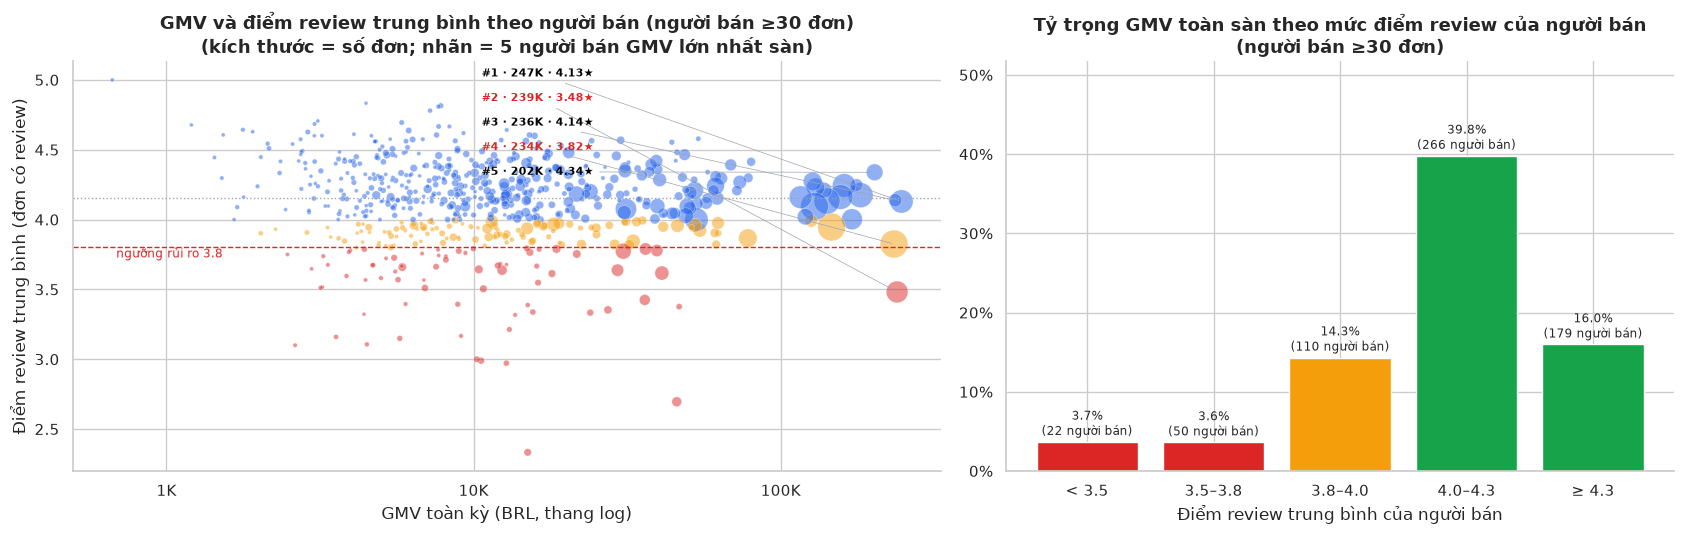

Người bán ≥30 đơn: 627 (21% số người bán) tạo 77.3% GMV toàn sàn
Doanh thu rủi ro (<3.8★): 72 người bán, 1.13 triệu BRL = 7.3% GMV toàn sàn; trong đó tầng Lớn + Chiến lược: 12 người bán, 0.62 triệu
Tương quan Spearman (tương quan trên hạng) GMV ~ review: -0.09; GMV ~ % trễ: +0.09
                       n  review  negative   late
tier                                             
Siêu nhỏ (< 1K)        1   5.000     0.000  0.000
Nhỏ (1K–5K)          133   4.163     0.129  0.065
Vừa (5K–20K)         352   4.115     0.141  0.066
Lớn (20K–100K)       122   4.113     0.141  0.068
Chiến lược (≥ 100K)   19   4.095     0.144  0.071
             sellers         gmv  gmv_share
review_band                                
< 3.5             22   570072.11      0.037
3.5–3.8           50   559820.04      0.036
3.8–4.0          110  2222491.10      0.143
4.0–4.3          266  6177467.58      0.398
≥ 4.3            179  2479313.38      0.160

10 người bán GMV lớn nhất sàn:
 gmv_rank   seller seller_sta

In [10]:
rated = sellers[sellers.orders >= MIN_SELLER_ORDERS]
review_mix = rated.groupby("review_band", observed=False).agg(sellers=("seller_id", "size"), gmv=("gmv", "sum"))
review_mix["gmv_share"] = review_mix.gmv / TOTAL_GMV
risk_bands = REVIEW_LABELS[:REVIEW_EDGES.index(RISK_REVIEW)]
at_risk = rated[rated.review_band.isin(risk_bands)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
point_colors = np.where(rated.avg_review < RISK_REVIEW, C_BAD, np.where(rated.avg_review < GOOD_REVIEW, C_ACCENT, C_MAIN))
ax1.scatter(rated.gmv, rated.avg_review, s=np.clip(rated.orders / 4, 8, 400), c=point_colors, alpha=0.5, edgecolor="white", lw=0.4)
ax1.set_xscale("log"); ax1.axhline(RISK_REVIEW, color=C_BAD, ls="--", lw=1)
ax1.axhline(rated.avg_review.median(), color=C_GREY, ls=":", lw=1)
ax1.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:,.0f}K"))
ax1.text(rated.gmv.min(), RISK_REVIEW, f" ngưỡng rủi ro {RISK_REVIEW:g}", ha="left", va="top", fontsize=8.5, color=C_BAD)
for j, (_, r) in enumerate(rated.nsmallest(5, "gmv_rank").iterrows()):   # 5 người bán GMV lớn nhất sàn
    ax1.annotate(f"#{r.gmv_rank} · {r.gmv/1e3:,.0f}K · {r.avg_review:.2f}★", (r.gmv, r.avg_review), fontsize=8,
                 xytext=(0.60, 0.97 - 0.06 * j), textcoords="axes fraction", ha="right", va="center",
                 color=C_BAD if r.avg_review < GOOD_REVIEW else "black", fontweight="bold",
                 arrowprops=dict(arrowstyle="-", color=C_GREY, lw=0.5))
ax1.set_xlabel("GMV toàn kỳ (BRL, thang log)"); ax1.set_ylabel("Điểm review trung bình (đơn có review)")
ax1.set_title(f"GMV và điểm review trung bình theo người bán (người bán ≥{MIN_SELLER_ORDERS} đơn)\n(kích thước = số đơn; nhãn = 5 người bán GMV lớn nhất sàn)")

band_colors = [C_BAD if b in risk_bands else (C_ACCENT if b == REVIEW_LABELS[len(risk_bands)] else C_GOOD) for b in REVIEW_LABELS]
mix_bars = ax2.bar(review_mix.index.astype(str), review_mix.gmv_share, color=band_colors)
ax2.bar_label(mix_bars, labels=[f"{g:.1%}\n({n} người bán)" for g, n in zip(review_mix.gmv_share, review_mix.sellers)], fontsize=8.5, padding=2)
pct_axis(ax2); ax2.set_ylim(0, review_mix.gmv_share.max() * 1.3); ax2.set_xlabel("Điểm review trung bình của người bán")
ax2.set_title(f"Tỷ trọng GMV toàn sàn theo mức điểm review của người bán\n(người bán ≥{MIN_SELLER_ORDERS} đơn)")
plt.tight_layout(); plt.show()

print(f"Người bán ≥{MIN_SELLER_ORDERS} đơn: {len(rated)} ({len(rated)/len(sellers):.0%} số người bán) tạo {rated.gmv.sum()/TOTAL_GMV:.1%} GMV toàn sàn")
print(f"Doanh thu rủi ro (<{RISK_REVIEW:g}★): {len(at_risk)} người bán, {at_risk.gmv.sum()/1e6:.2f} triệu BRL = {at_risk.gmv.sum()/TOTAL_GMV:.1%} GMV toàn sàn; "
      f"trong đó tầng {' + '.join(TOP_TIERS)}: {at_risk.tier.isin(TOP_TIER_LABELS).sum()} người bán, "
      f"{at_risk[at_risk.tier.isin(TOP_TIER_LABELS)].gmv.sum()/1e6:.2f} triệu")
print(f"Tương quan Spearman (tương quan trên hạng) GMV ~ review: {rated.gmv.rank().corr(rated.avg_review.rank()):+.2f}; "
      f"GMV ~ % trễ: {rated.gmv.rank().corr(rated.late_rate.rank()):+.2f}")
print(rated.groupby("tier", observed=True).agg(n=("seller_id", "size"), review=("avg_review", "mean"), negative=("negative_rate", "mean"),
                                               late=("late_rate", "mean")).round(3).to_string())
print(review_mix.round(3).to_string())
print("\n10 người bán GMV lớn nhất sàn:")
print(sellers.nsmallest(10, "gmv_rank").assign(seller=lambda d: d.seller_id.str[:8])
      [["gmv_rank", "seller", "seller_state", "orders", "gmv", "avg_review", "negative_rate", "late_rate"]].round(3).to_string(index=False))

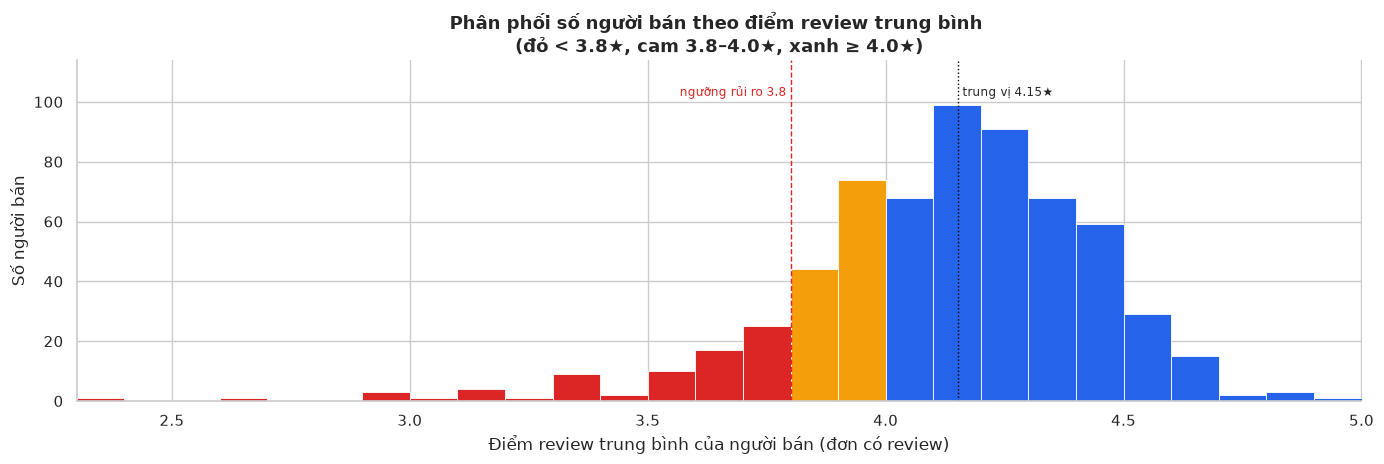

count    627.00
mean       4.13
std        0.31
min        2.33
10%        3.78
25%        3.96
50%        4.15
75%        4.33
90%        4.47
max        5.00
< 3.8★: 72 người bán (11.5%) | ≥ 4.5★: 51 người bán (8.1%)


In [11]:
# Phân phối số người bán theo điểm review trung bình (người bán ≥ MIN_SELLER_ORDERS đơn)
REVIEW_BIN = 0.1
bins = np.arange(np.floor(rated.avg_review.min() / REVIEW_BIN) * REVIEW_BIN, 5 + REVIEW_BIN, REVIEW_BIN)
counts, edges = np.histogram(rated.avg_review, bins=bins)
bin_colors = [C_BAD if left < RISK_REVIEW else (C_ACCENT if left < GOOD_REVIEW else C_MAIN) for left in edges[:-1]]
median_review = rated.avg_review.median()

fig, ax = plt.subplots(figsize=(14, 4.8))
ax.bar(edges[:-1], counts, width=REVIEW_BIN, align="edge", color=bin_colors, edgecolor="white", lw=0.6)
ax.axvline(RISK_REVIEW, color=C_BAD, ls="--", lw=1)
ax.axvline(median_review, color="black", ls=":", lw=1)
ax.text(RISK_REVIEW, counts.max() * 1.02, f"ngưỡng rủi ro {RISK_REVIEW:g} ", ha="right", va="bottom", fontsize=8.5, color=C_BAD)
ax.text(median_review, counts.max() * 1.02, f" trung vị {median_review:.2f}★", ha="left", va="bottom", fontsize=8.5)
ax.set_ylim(0, counts.max() * 1.15); ax.set_xlim(edges[0], 5)
ax.set_xlabel("Điểm review trung bình của người bán (đơn có review)"); ax.set_ylabel("Số người bán")
ax.set_title(f"Phân phối số người bán theo điểm review trung bình "
             f"\n(đỏ < {RISK_REVIEW:g}★, cam {RISK_REVIEW:g}–{GOOD_REVIEW:.1f}★, xanh ≥ {GOOD_REVIEW:.1f}★)")
plt.tight_layout(); plt.show()

print(rated.avg_review.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(2).to_string())
print(f"< {RISK_REVIEW:g}★: {(rated.avg_review < RISK_REVIEW).sum()} người bán ({(rated.avg_review < RISK_REVIEW).mean():.1%}) | "
      f"≥ 4.5★: {(rated.avg_review >= 4.5).sum()} người bán ({(rated.avg_review >= 4.5).mean():.1%})")

> **🔎 Kết quả chính**
> - 627 người bán có ≥ 30 đơn (21% người bán) tạo **77,3% GMV**.
> - **Quy mô không đi kèm chất lượng**: tương quan hạng GMV ↔ điểm review gần 0 (−0,09); điểm TB các tầng gần như bằng nhau (4,10–4,16★).
> - **Doanh thu rủi ro: 1,13 triệu BRL = 7,3% GMV toàn sàn** nằm ở 72 người bán dưới 3,8★, riêng 12 người bán tầng Lớn / Chiến lược nắm 0,62 triệu.
> - Trong **top 5 người bán lớn nhất**, có 2 người dưới 4,0★: **#2** `7c67e144…` (SP, 239K BRL, **3,48★**, 26,1% đơn không hài lòng) và **#4** `4a3ca931…` (SP, 234K, 3,83★, 19,5%).

## 6. Phân tầng chất lượng người bán (kỳ này)
*Câu hỏi: "Người bán nào vừa giao đúng hạn vừa được đánh giá cao? Ai là 'vùng đỏ' cần giám sát? Có phải một nhóm nhỏ gây ra phần lớn đơn không hài lòng?"*

- Biểu đồ đầu dựng lại scatter *Phân tầng chất lượng người bán* của p6: trục X = % đơn giao đúng hạn, trục Y = điểm review TB, kích thước = GMV kỳ này;
  chỉ người bán có ≥ 10 đơn trong kỳ (giống Power BI).
- **Vùng đỏ** (% trễ > 20% hoặc review < 3,5) và **ngôi sao** (% trễ ≤ 8% và review ≥ 4,2) là **ngưỡng EDA, không có trên Power BI**,
  chỉ áp cho người bán có ≥ `GOLD.SELLER_MIN_ORDERS` đơn hợp lệ trong kỳ này. Tỷ trọng GMV tính trên **GMV toàn sàn kỳ này**.
- Phần sau (từ `customer_experience` §7 cũ) xếp người bán theo **số đơn không hài lòng** trên toàn bộ lịch sử.

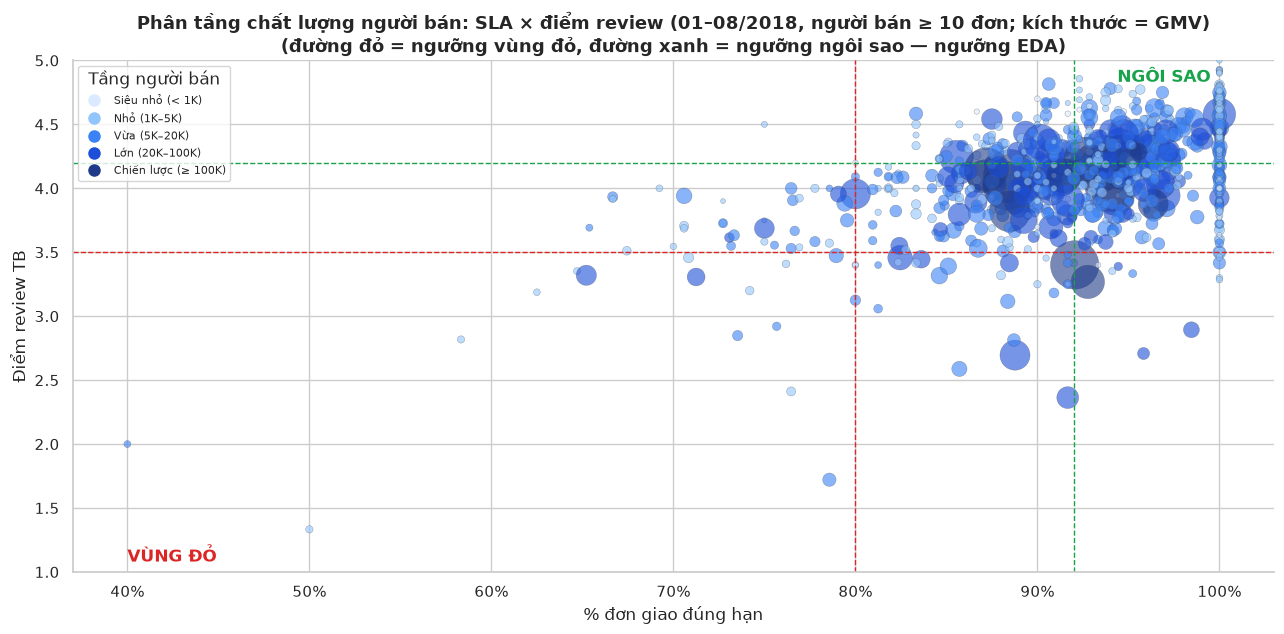

Người bán ≥ 30 đơn trong 01–08/2018: 388 người, 67.5% GMV toàn sàn kỳ này
          sellers         gmv   late  review  negative  gmv_share_of_market
group                                                                      
Vùng đỏ        26   434162.19  0.194   3.318     0.346                0.052
Ở giữa        241  3707633.62  0.087   4.019     0.163                0.441
Ngôi sao      121  1526955.63  0.037   4.400     0.077                0.182

Trong vùng đỏ: do trễ > 20%: 16 | do review < 3.5: 16 | cả hai: 6

15 người bán vùng đỏ có GMV kỳ này lớn nhất (danh sách giám sát):
  seller seller_state                tier  orders       gmv  late_rate  avg_review  negative_rate
7c67e144           SP Chiến lược (≥ 100K)     485 120504.38      0.079       3.401          0.284
5dceca12           SP Chiến lược (≥ 100K)      83  57221.86      0.072       3.268          0.366
2eb70248           SP      Lớn (20K–100K)     202  45860.10      0.112       2.695          0.503
88460e8e           P

In [12]:
sq = q(f"""
    WITH so AS (SELECT DISTINCT seller_id, order_id FROM item_ps WHERE {P.cur}),
    g AS (SELECT seller_id, sum(gmv) AS gmv FROM item_ps WHERE {P.cur} GROUP BY 1)
    SELECT so.seller_id, arbitrary(s.state) AS seller_state, count(*) AS orders,
           avg(o.review_score) AS avg_review, avg(o.is_negative) AS negative_rate, avg(o.is_late) AS late_rate,
           1 - avg(o.is_late) AS on_time, arbitrary(g.gmv) AS gmv
    FROM so JOIN order_base o ON o.order_id = so.order_id JOIN g ON g.seller_id = so.seller_id
    LEFT JOIN sellers s ON s.seller_id = so.seller_id
    GROUP BY 1""")
sq = sq.merge(sellers[["seller_id", "tier"]], on="seller_id", how="left")
GMV_CUR = scalar(f"SELECT sum(gmv) FROM item_ps WHERE {P.cur}")

plot_df = sq[(sq.orders >= PBI_MIN_SELLER_ORDERS) & sq.on_time.notna() & sq.avg_review.notna()]
fig, ax = plt.subplots(figsize=(13, 6.5))
tier_colors = dict(zip(SELLER_TIER_LABELS, SEQ_BLUES))
ax.scatter(plot_df.on_time, plot_df.avg_review, s=plot_df.gmv / plot_df.gmv.max() * 1500 + 8,
           c=plot_df.tier.astype(str).map(tier_colors).fillna(C_GREY), alpha=0.6, edgecolor=C_MUTED_TEXT, lw=0.3)
ax.axvline(1 - RED_LATE, color=C_BAD, ls="--", lw=1); ax.axhline(RED_REVIEW, color=C_BAD, ls="--", lw=1)
ax.axvline(1 - STAR_LATE, color=C_GOOD, ls="--", lw=1); ax.axhline(STAR_REVIEW, color=C_GOOD, ls="--", lw=1)
ax.text(0.995, 4.95, "NGÔI SAO", ha="right", va="top", color=C_GOOD, fontweight="bold")
ax.text(plot_df.on_time.min(), 1.05, "VÙNG ĐỎ", ha="left", va="bottom", color=C_BAD, fontweight="bold")
pct_axis(ax, "x"); ax.set_ylim(1, 5); ax.set_xlabel("% đơn giao đúng hạn"); ax.set_ylabel("Điểm review TB")
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=l, markersize=8) for l, c in tier_colors.items()]
ax.legend(handles=handles, title="Tầng người bán", loc="upper left", fontsize=8)
ax.set_title(f"Phân tầng chất lượng người bán: SLA × điểm review ({P.label_cur}, người bán ≥ {PBI_MIN_SELLER_ORDERS} đơn; kích thước = GMV)\n"
             f"(đường đỏ = ngưỡng vùng đỏ, đường xanh = ngưỡng ngôi sao — ngưỡng EDA)")
plt.tight_layout(); plt.show()

rated_cur = sq[sq.orders >= MIN_SELLER_ORDERS].copy()
rated_cur["group"] = np.select(
    [(rated_cur.late_rate > RED_LATE) | (rated_cur.avg_review < RED_REVIEW),
     (rated_cur.late_rate <= STAR_LATE) & (rated_cur.avg_review >= STAR_REVIEW)],
    ["Vùng đỏ", "Ngôi sao"], "Ở giữa")
grp = rated_cur.groupby("group").agg(sellers=("seller_id", "size"), gmv=("gmv", "sum"), late=("late_rate", "mean"),
                                     review=("avg_review", "mean"), negative=("negative_rate", "mean"))
grp["gmv_share_of_market"] = grp.gmv / GMV_CUR
print(f"Người bán ≥ {MIN_SELLER_ORDERS} đơn trong {P.label_cur}: {len(rated_cur)} người, {rated_cur.gmv.sum() / GMV_CUR:.1%} GMV toàn sàn kỳ này")
print(grp.reindex(["Vùng đỏ", "Ở giữa", "Ngôi sao"]).round(3).to_string())
print(f"\nTrong vùng đỏ: do trễ > {RED_LATE:.0%}: {(rated_cur.late_rate > RED_LATE).sum()} | do review < {RED_REVIEW}: "
      f"{(rated_cur.avg_review < RED_REVIEW).sum()} | cả hai: {((rated_cur.late_rate > RED_LATE) & (rated_cur.avg_review < RED_REVIEW)).sum()}")
print("\n15 người bán vùng đỏ có GMV kỳ này lớn nhất (danh sách giám sát):")
print(rated_cur[rated_cur.group == "Vùng đỏ"].nlargest(15, "gmv").assign(seller=lambda d: d.seller_id.str[:8])
      [["seller", "seller_state", "tier", "orders", "gmv", "late_rate", "avg_review", "negative_rate"]].round(3).to_string(index=False))

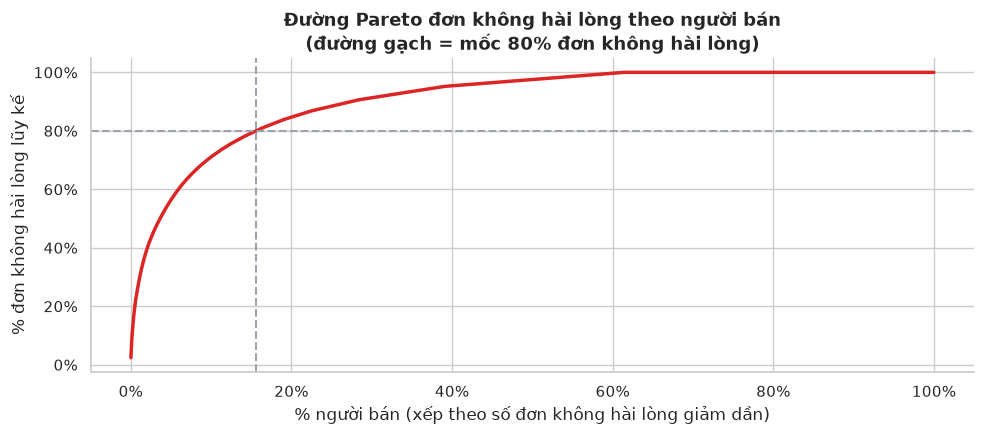

Số người bán: 3,084 | có ≥30 đơn: 627 | 80% đơn không hài lòng đến từ 15.6% người bán


In [13]:
seller_perf = q(f'''
    WITH order_seller AS (SELECT DISTINCT order_id, seller_id FROM order_items)
    SELECT s.seller_id, s.state AS seller_state, {CX_METRICS},
           coalesce(sum(is_negative), 0) AS negative_orders, avg(is_late) AS late_rate
    FROM order_seller JOIN order_cx USING (order_id)
    LEFT JOIN sellers s USING (seller_id)
    GROUP BY 1, 2''')
active = seller_perf[seller_perf.orders >= MIN_SELLER_ORDERS]

pareto = seller_perf.sort_values("negative_orders", ascending=False)
pareto["cum_share"] = pareto.negative_orders.cumsum() / pareto.negative_orders.sum()
pareto["seller_share"] = np.arange(1, len(pareto) + 1) / len(pareto)
seller_share_at_80 = pareto.loc[pareto.cum_share >= 0.8, "seller_share"].iloc[0]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(pareto.seller_share, pareto.cum_share, color=C_BAD, lw=2.5)
ax.axhline(0.8, color=C_GREY, ls="--"); ax.axvline(seller_share_at_80, color=C_GREY, ls="--")
pct_axis(ax); pct_axis(ax, "x"); ax.set_xlabel("% người bán (xếp theo số đơn không hài lòng giảm dần)"); ax.set_ylabel("% đơn không hài lòng lũy kế")
ax.set_title(f"Đường Pareto đơn không hài lòng theo người bán\n(đường gạch = mốc 80% đơn không hài lòng)"); plt.tight_layout(); plt.show()
print(f"Số người bán: {len(seller_perf):,} | có ≥{MIN_SELLER_ORDERS} đơn: {len(active):,} | 80% đơn không hài lòng đến từ {seller_share_at_80:.1%} người bán")

In [14]:
watchlist = active.sort_values("negative_orders", ascending=False).head(15)
print(watchlist[["seller_id", "seller_state", "orders", "avg_score", "negative_orders", "negative_rate", "late_rate"]]
      .round(3).to_string(index=False))

                       seller_id seller_state  orders  avg_score  negative_orders  negative_rate  late_rate
4a3ca9315b744ce9f8e9374361493884           SP    1790      3.824              343          0.195      0.098
6560211a19b47992c3666cc44a7e94c0           SP    1803      3.935              308          0.173      0.053
7c67e1448b00f6e969d365cea6b010ab           SP     981      3.482              252          0.261      0.092
cc419e0650a3c5ba77189a1882b7556a           SP    1701      4.079              249          0.150      0.053
1f50f920176fa81dab994f9023523100           SP    1396      4.130              197          0.142      0.089
ea8482cd71df3c1969d7b9473ff13abc           SP    1121      3.997              171          0.154      0.087
1025f0e2d44d7041d6cf58b6550e0bfa           SP     903      4.002              152          0.172      0.079
4869f7a5dfa277a7dca6462dcf3b52b2           SP    1120      4.127              151          0.136      0.106
da8622b14eb17ae2831f4ac5b9da

In [15]:
# Người bán và khách cùng bang vs khác bang (chỉ đơn mà mọi người bán cùng 1 bang)
route = q(f'''
    WITH seller_state_order AS (
        SELECT i.order_id, arbitrary(s.state) AS seller_state, count(DISTINCT s.state) AS n_seller_states
        FROM (SELECT DISTINCT order_id, seller_id FROM order_items) i
        JOIN sellers s USING (seller_id) GROUP BY 1)
    SELECT CASE WHEN seller_state = customer_state THEN 'Cùng bang' ELSE 'Khác bang' END AS route,
           {CX_METRICS}, avg(delivery_days) AS avg_delivery_days, avg(is_late) AS late_rate
    FROM delivered JOIN seller_state_order USING (order_id)
    WHERE n_seller_states = 1
    GROUP BY 1''')
print(route.round(3).to_string(index=False))

    route  orders  avg_score  negative_rate  avg_delivery_days  late_rate
Khác bang   60536      4.105          0.139             14.784      0.082
Cùng bang   34069      4.268          0.103              7.531      0.046


> **🔎 Kết quả chính**
> - Kỳ này có 388 người bán ≥ 30 đơn, nắm 67,5% GMV toàn sàn. Theo ngưỡng EDA:
>   - **Vùng đỏ: 26 người bán = 5,2% GMV** (trễ TB 19,4%, review 3,32★, 34,6% đơn không hài lòng); 16 người do trễ > 20%, 16 người do review < 3,5, 6 người cả hai.
>   - **Ngôi sao: 121 người bán = 18,2% GMV** (trễ 3,7%, review 4,40★, 7,7% không hài lòng) → hình mẫu để nhân rộng / ưu tiên hiển thị.
>   - 241 người còn lại (44,1% GMV) ở giữa.
> - Người bán vùng đỏ lớn nhất là **#2 sàn `7c67e144…`** (tầng chiến lược, 121K BRL kỳ này, 3,40★, 28,4% không hài lòng) — vấn đề nằm ở **review chứ không ở giao trễ** (7,9%) → cần xem bình luận / chất lượng sản phẩm, không phải logistics.
> - *So với kế hoạch ban đầu* (135 người bán vùng đỏ nắm 26,3% GMV): với ngưỡng và tập người bán ≥ 30 đơn kỳ này, vùng đỏ nhỏ hơn nhiều — con số cũ không được dữ liệu hiện tại ủng hộ.
> - Toàn lịch sử: **15,6% người bán gây ra 80% đơn không hài lòng**; watchlist 15 người toàn ở SP. Đơn người bán **cùng bang** với khách: 7,5 ngày, 4,6% trễ, 10,3% không hài lòng; **khác bang**: 14,8 ngày, 8,2% trễ, 13,9% không hài lòng.

## 7. Cung – cầu theo vùng và ngành hàng
*Câu hỏi: "Vùng nào, ngành nào khách phải mua từ người bán ở vùng khác? Nên tuyển người bán ở đâu, ngành gì?"*

- **Lệch pha** của (vùng *r*, ngành *c*) = (GMV người bán **đặt tại** *r* bán ra trong ngành *c* − GMV khách **ở** *r* mua ngành *c*) / GMV khách *r* mua ngành *c*,
  giống measure `Region Category Gap` của ma trận trên p6. **Âm = thiếu cung tại chỗ** (−100% = không có người bán nào trong vùng), dương = dư cung, xuất sang vùng khác.
- 12 ngành = 12 ngành có GMV lớn nhất toàn kỳ (giống `is_top12_category` của Gold). Tính trên kỳ này.
- Bên phải: % dòng hàng phải giao **liên vùng** và **mật độ người bán** (người bán đặt tại vùng / 1.000 khách của vùng) theo vùng của khách.

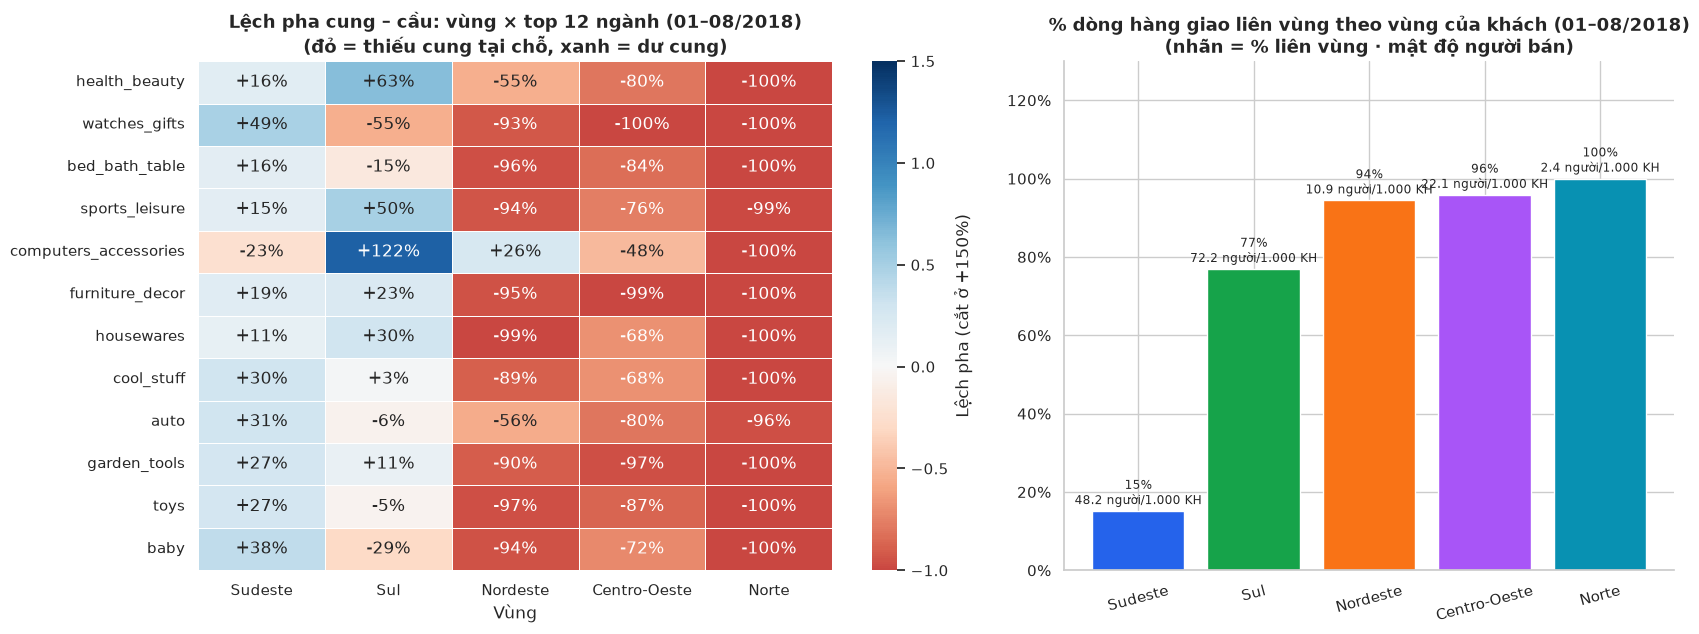

region                Sudeste    Sul Nordeste Centro-Oeste  Norte
category                                                         
health_beauty            +16%   +63%     -55%         -80%  -100%
watches_gifts            +49%   -55%     -93%        -100%  -100%
bed_bath_table           +16%   -15%     -96%         -84%  -100%
sports_leisure           +15%   +50%     -94%         -76%   -99%
computers_accessories    -23%  +122%     +26%         -48%  -100%
furniture_decor          +19%   +23%     -95%         -99%  -100%
housewares               +11%   +30%     -99%         -68%  -100%
cool_stuff               +30%    +3%     -89%         -68%  -100%
auto                     +31%    -6%     -56%         -80%   -96%
garden_tools             +27%   +11%     -90%         -97%  -100%
toys                     +27%    -5%     -97%         -87%  -100%
baby                     +38%   -29%     -94%         -72%  -100%

              inter_region  customers  sellers  density
region             

In [16]:
top12 = q(f"SELECT category FROM item_ps GROUP BY 1 ORDER BY sum(gmv) DESC, category LIMIT {GOLD.TOP_FLOW_CATEGORY_N}").category.tolist()
cats_sql = ", ".join(f"'{c}'" for c in top12)
dem = q(f"SELECT customer_region AS region, category, sum(gmv) AS demand FROM item_ps WHERE {P.cur} AND category IN ({cats_sql}) GROUP BY 1, 2")
sup = q(f"SELECT seller_region AS region, category, sum(gmv) AS supply FROM item_ps WHERE {P.cur} AND category IN ({cats_sql}) AND seller_region IS NOT NULL GROUP BY 1, 2")
sd_rc = dem.merge(sup, on=["region", "category"], how="left").fillna({"supply": 0})
sd_rc["gap"] = (sd_rc.supply - sd_rc.demand) / sd_rc.demand
gap = sd_rc.pivot(index="category", columns="region", values="gap").reindex(index=top12, columns=REGIONS)

reg_q = q(f"""SELECT customer_region AS region, avg(CAST(seller_region <> customer_region AS DOUBLE)) AS inter_region,
                       count(DISTINCT customer_unique_id) AS customers
                FROM item_ps WHERE {P.cur} AND seller_region IS NOT NULL GROUP BY 1""").set_index("region")
reg_q["sellers"] = q(f"SELECT seller_region AS region, count(DISTINCT seller_id) AS sellers FROM item_ps WHERE {P.cur} GROUP BY 1").set_index("region").sellers
reg_q = reg_q.reindex(REGIONS).fillna({"sellers": 0})
reg_q["density"] = reg_q.sellers / reg_q.customers * 1000

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(gap.clip(upper=1.5), annot=gap.map(lambda v: f"{v:+.0%}"), fmt="", cmap="RdBu", center=0, vmin=-1, vmax=1.5, ax=ax1,
            cbar_kws={"label": "Lệch pha (cắt ở +150%)"}, linewidths=0.4, linecolor="white")
ax1.set_xlabel("Vùng"); ax1.set_ylabel(""); ax1.set_title(f"Lệch pha cung – cầu: vùng × top {len(top12)} ngành ({P.label_cur})\n(đỏ = thiếu cung tại chỗ, xanh = dư cung)")
x = np.arange(len(REGIONS))
b = ax2.bar(x, reg_q.inter_region, color=region_colors())
ax2.bar_label(b, labels=[f"{v:.0%}\n{d:.1f} người/1.000 KH" for v, d in zip(reg_q.inter_region, reg_q.density)], fontsize=8.5, padding=2)
ax2.set_xticks(x, REGIONS, rotation=15); pct_axis(ax2); ax2.set_ylim(0, 1.3)
ax2.set_title(f"% dòng hàng giao liên vùng theo vùng của khách ({P.label_cur})\n(nhãn = % liên vùng · mật độ người bán)")
plt.tight_layout(); plt.show()

print(gap.map(lambda v: f"{v:+.0%}").to_string()); print()
print(reg_q.round(3).to_string())
gold_top12 = q("SELECT DISTINCT category FROM iceberg.gold.fact_item_sales WHERE is_top12_category = 'Có'").category.tolist()
print(f"\nTop {len(top12)} ngành trùng Gold is_top12_category: {len(set(top12) & set(gold_top12))}/{len(top12)}")

> **🔎 Kết quả chính**
> - **Nordeste thiếu cung ở gần như mọi ngành lớn**: −89% đến −99% ở watches_gifts, bed_bath_table, sports_leisure, furniture_decor, housewares, toys, baby; nhẹ hơn ở health_beauty (−55%) và auto (−56%); riêng computers_accessories dư (+26%). **Norte −96% đến −100%** ở mọi ngành; Centro-Oeste −48% đến −100%.
> - **Sul dư cung** computers_accessories (+122%), health_beauty (+63%), sports_leisure (+50%) nhưng thiếu watches_gifts (−55%), baby (−29%). Sudeste dư nhẹ hầu hết các ngành, trừ computers_accessories (−23%).
> - Hệ quả: **94% dòng hàng của khách Nordeste, 96% Centro-Oeste, 100% Norte phải giao liên vùng** (Sudeste 15%). Mật độ người bán Nordeste chỉ **10,9 người / 1.000 khách** so với 48,2 ở Sudeste và 72,2 ở Sul.
> - → **Quyết định ④**: ưu tiên thu hút người bán **đặt tại Nordeste** ở các ngành health_beauty, watches_gifts, bed_bath_table, sports_leisure, housewares — đúng các ngành "Ngôi sao" / quy mô lớn của `03_product`, và đúng vùng "Cơ hội" của `02_geo` §11. 12 ngành khớp 12/12 `is_top12_category` của Gold.

## 8. Thời gian bàn giao & tải của người bán
*Câu hỏi: "Người bán mất bao lâu để giao hàng cho đơn vị vận chuyển? Bàn giao chậm có gắn với giao trễ không? Người bán nhiều đơn có bị quá tải làm giảm chất lượng không?"*

- **Thời gian bàn giao** = `order_delivered_carrier_date − order_approved_at` (ngày, theo giờ / 24) của đơn hợp lệ kỳ này chỉ có **một** người bán,
  bỏ các đơn có mốc thời gian ngược (âm).
- Biểu đồ phải: số đơn toàn kỳ × điểm review của người bán ≥ `GOLD.SELLER_MIN_ORDERS` đơn (hexbin) để kiểm tra giả thuyết "càng nhiều đơn càng quá tải".

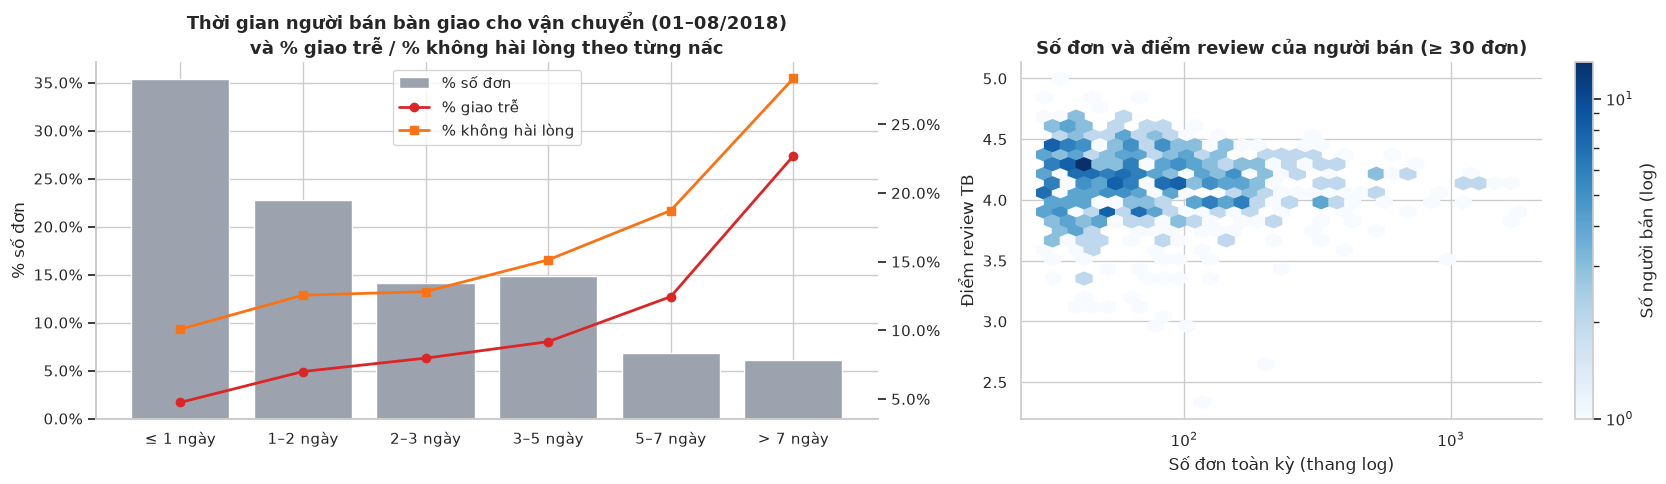

Thời gian bàn giao P25/P50/P75/P90 (ngày): [0.8, 1.7, 3.3, 5.8]
    band  orders  late_rate  negative_rate  delivery_days  share
≤ 1 ngày   18139      0.048          0.101          9.130  0.354
1–2 ngày   11686      0.070          0.126         11.026  0.228
2–3 ngày    7247      0.080          0.128         12.036  0.141
3–5 ngày    7625      0.092          0.151         13.497  0.149
5–7 ngày    3499      0.125          0.187         15.744  0.068
> 7 ngày    3115      0.227          0.283         21.751  0.061
Spearman số đơn ~ điểm review (người bán ≥ 30 đơn): -0.10; số đơn ~ % trễ: +0.08
tier
Siêu nhỏ (< 1K)        1.9
Nhỏ (1K–5K)            2.0
Vừa (5K–20K)           2.1
Lớn (20K–100K)         2.3
Chiến lược (≥ 100K)    2.1


In [17]:
con.execute(f"""
CREATE OR REPLACE TABLE handling AS
WITH one_seller AS (SELECT order_id, arbitrary(seller_id) AS seller_id FROM order_items GROUP BY 1 HAVING count(DISTINCT seller_id) = 1)
SELECT b.order_id, os.seller_id, b.is_late, b.is_negative, b.delivery_days,
       date_diff('hour', f.order_approved_at, f.order_delivered_carrier_date) / 24.0 AS handling_days
FROM order_base b JOIN orders f ON f.order_id = b.order_id JOIN one_seller os ON os.order_id = b.order_id
WHERE b.is_valid = 1 AND {P.cur_on('b.purchase_month')}
  AND f.order_approved_at IS NOT NULL AND f.order_delivered_carrier_date IS NOT NULL
  AND f.order_delivered_carrier_date >= f.order_approved_at""")
HANDLING_BINS = [(1, "≤ 1 ngày"), (2, "1–2 ngày"), (3, "2–3 ngày"), (5, "3–5 ngày"), (7, "5–7 ngày")]
HANDLING_ORDER = [l for _, l in HANDLING_BINS] + ["> 7 ngày"]
hb = ordered(q(f"""SELECT {band_sql('handling_days', HANDLING_BINS, '> 7 ngày', upper_inclusive=True)} AS band, count(*) AS orders,
                           avg(is_late) AS late_rate, avg(is_negative) AS negative_rate, avg(delivery_days) AS delivery_days
                    FROM handling GROUP BY 1"""), "band", HANDLING_ORDER)
hb["share"] = hb.orders / hb.orders.sum()
hstats = scalar(f"SELECT {quantile_sql('handling_days', [0.25, 0.5, 0.75, 0.9])} FROM handling")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [1.2, 1]})
xb = np.arange(len(hb))
ax1.bar(xb, hb.share, color=C_GREY, label="% số đơn")
ax1.set_xticks(xb, hb.band); pct_axis(ax1); ax1.set_ylabel("% số đơn")
ax1b = ax1.twinx(); ax1b.grid(False)
ax1b.plot(xb, hb.late_rate, color=C_BAD, marker="o", lw=2, label="% giao trễ")
ax1b.plot(xb, hb.negative_rate, color=C_ORANGE, marker="s", lw=2, label="% không hài lòng"); pct_axis(ax1b)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax1b.get_legend_handles_labels(); ax1.legend(h1 + h2, l1 + l2, loc="upper center")
ax1.set_title(f"Thời gian người bán bàn giao cho vận chuyển ({P.label_cur})\nvà % giao trễ / % không hài lòng theo từng nấc")

rated_all = sellers[sellers.orders >= MIN_SELLER_ORDERS]
hx = ax2.hexbin(rated_all.orders, rated_all.avg_review, gridsize=30, xscale="log", bins="log", cmap="Blues", mincnt=1)
fig.colorbar(hx, ax=ax2, label="Số người bán (log)")
ax2.set_xlabel("Số đơn toàn kỳ (thang log)"); ax2.set_ylabel("Điểm review TB")
ax2.set_title(f"Số đơn và điểm review của người bán (≥ {MIN_SELLER_ORDERS} đơn)")
plt.tight_layout(); plt.show()

print(f"Thời gian bàn giao P25/P50/P75/P90 (ngày): {[round(v, 1) for v in hstats]}")
print(hb.round(3).to_string(index=False))
print(f"Spearman số đơn ~ điểm review (người bán ≥ {MIN_SELLER_ORDERS} đơn): {rated_all.orders.rank().corr(rated_all.avg_review.rank()):+.2f}; "
      f"số đơn ~ % trễ: {rated_all.orders.rank().corr(rated_all.late_rate.rank()):+.2f}")
tier_handling = q("SELECT seller_id, avg(handling_days) AS handling_days FROM handling GROUP BY 1").merge(sellers[["seller_id", "tier"]], on="seller_id")
print(tier_handling.groupby("tier", observed=True).handling_days.median().round(2).rename("trung vị bàn giao (ngày)").to_string())

> **🔎 Kết quả chính**
> - Người bán bàn giao cho vận chuyển khá nhanh: trung vị **1,7 ngày**, 90% đơn trong 5,8 ngày.
> - **Bàn giao chậm đi cùng giao trễ**: đơn bàn giao ≤ 1 ngày có 4,8% trễ, 10,1% không hài lòng; bàn giao > 7 ngày (6,1% đơn) có **22,7% trễ, 28,3% không hài lòng**, tổng thời gian giao 21,8 ngày so với 9,1 ngày → SLA bàn giao là chỉ tiêu nên đưa vào hợp đồng người bán.
> - Thời gian bàn giao trung vị gần như như nhau giữa các tầng (1,9–2,3 ngày).
> - **Không có dấu hiệu quá tải**: tương quan hạng giữa số đơn và điểm review chỉ −0,10, với % trễ +0,08 → giả thuyết "người bán càng nhiều đơn càng giảm chất lượng" **không được dữ liệu ủng hộ**.

## 9. Đối chiếu với Gold (nguồn của Power BI)
Thẻ của trang p6 (kỳ này) khớp `fact_item_sales` / `fact_order_summary`; tầng người bán và mức review khớp `dim_seller`.

In [18]:
GI, GO, GS = "iceberg.gold.fact_item_sales", "iceberg.gold.fact_order_summary", "iceberg.gold.dim_seller"
gcur = gold_period_where(P.cur)
c = p6_cards(P.cur)
tier_eda = sellers.tier.cat.codes.value_counts().sort_index()
checks = [
    ("Tỷ lệ giao liên vùng", c["inter_region"],
     f"""SELECT avg(CAST(i.seller_region <> o.region AS DOUBLE)) FROM {GI} i JOIN {GO} o ON o.order_key = i.order_key
          WHERE {gcur.replace('purchase_date', 'i.purchase_date')} AND i.seller_region IS NOT NULL"""),
    ("Giao thực tế TB (ngày)", c["sla_actual"], f"SELECT avg(delivery_days) FROM {GO} WHERE is_valid = 1 AND is_late IS NOT NULL AND {gcur}"),
    ("Cam kết TB (ngày)", c["sla_promised"], f"SELECT avg(estimated_delivery_days) FROM {GO} WHERE is_valid = 1 AND is_late IS NOT NULL AND {gcur}"),
    ("Người bán có đơn (toàn kỳ)", len(sellers), f"SELECT count(*) FROM {GS}"),
    ("GMV người bán (toàn kỳ)", TOTAL_GMV, f"SELECT sum(gmv) FROM {GS}"),
    ("Người bán ≥ 30 đơn có review", sellers.review_band.notna().sum(), f"SELECT count(*) FROM {GS} WHERE review_band <> '{GOLD.SELLER_REVIEW_BAND_FEW_ORDERS}'"),
]
checks += [(f"Tầng: {SELLER_TIER_LABELS[i]}", n, f"SELECT count(*) FROM {GS} WHERE seller_tier_order = {i + 1}") for i, n in tier_eda.items()]
reconcile(checks)

,EDA (Silver),Gold,Sai lệch,Khớp
Chỉ số,,,,
Tỷ lệ giao liên vùng,0.3674,0.3674,0.00e+00,True
Giao thực tế TB (ngày),12.1634,12.1634,0.00e+00,True
Cam kết TB (ngày),23.4379,23.4379,0.00e+00,True
Người bán có đơn (toàn kỳ),"3,042","3,042",0.00e+00,True
GMV người bán (toàn kỳ),"15,526,006","15,526,006",1.08e-15,True
Người bán ≥ 30 đơn có review,627,627,0.00e+00,True
Tầng: Siêu nhỏ (< 1K),"1,527","1,527",0.00e+00,True
Tầng: Nhỏ (1K–5K),878,878,0.00e+00,True
Tầng: Vừa (5K–20K),490,490,0.00e+00,True


## 10. Đánh giá & tuyển chọn visual cho trang p6
Tiêu chí đưa lên Power BI: đọc hiểu trong ~10 giây, dẫn tới quyết định ④ (thu hút nhóm người bán nào, ở đâu), còn đúng khi lọc bằng slicer.

| Biểu đồ EDA | Câu hỏi / quyết định | Visual Power BI tương ứng (p6) hoặc "Phụ lục" | Lý do |
|---|---|---|---|
| §1 Thẻ p6 | Cung có gần cầu không | Thẻ *Tỷ lệ giao liên vùng*, *Chênh lệch cung – cầu*, *Giao thực tế / cam kết*, *Mật độ người bán* | Bốn con số đổi theo slicer vùng/bang |
| §1 Người bán hoạt động / GMV mỗi người bán theo tháng | Cung tăng nhanh hơn cầu? | Phụ lục | Lý do để **không** tuyển đại trà |
| §2 % người bán vs % GMV theo tầng | Nhóm nào nuôi sàn | *Tỷ trọng người bán và GMV theo tầng người bán* | Pareto người bán thấy ngay |
| §3 GMV theo tháng × cohort | Người bán mới có đóng góp không | *GMV theo tháng và phân nhóm người bán* | Cho thấy kênh tuyển người bán đang hiệu quả; tỷ lệ còn bán để phụ lục |
| §6 SLA × review, bong bóng GMV | Ai cần giám sát, ai đáng nhân rộng | *Phân tầng chất lượng người bán: GMV × SLA giao hàng × điểm đánh giá* | Một biểu đồ chỉ ra cả vùng đỏ lẫn ngôi sao |
| §7 Ma trận lệch pha vùng × ngành | **Tuyển người bán ở đâu, ngành gì** | *Ma trận lệch pha cung – cầu: vùng × ngành hàng (top 12)* | Trả lời thẳng quyết định ④ |
| §4 Tập trung top 3 người bán theo ngành | Ngành nào dễ tổn thương | Phụ lục | Rủi ro nguồn cung cho ngành Ngôi sao (`03_product`) |
| §5 Doanh thu rủi ro theo mức review | Bao nhiêu GMV trong tay người bán kém | Phụ lục | Con số đưa vào tờ trình |
| §6 Pareto đơn không hài lòng, watchlist, cùng/khác bang | Ai gây bất mãn | Phụ lục | Danh sách hành động cho bộ phận vận hành |
| §8 Thời gian bàn giao, số đơn × review | Quá tải có làm giảm chất lượng | Phụ lục | Bằng chứng khi HĐQT hỏi "tại sao người bán X trễ" |

In [19]:
con.close()